# **Data Preprocessing**


---



**Dataset:** Pima Indians Diabetes Dataset  

This dataset is used to predict the onset of diabetes among a population, a major global public-health issue. It contains real-world data quality problems (missing values disguised as zeros, outliers, skewed distributions), making it ideal for a preprocessing exercise.

**Source / Download link:** https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv  
(Original source: UCI Machine Learning Repository / National Institute of Diabetes and Digestive and Kidney Diseases — also mirrored on Kaggle: https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database)



 **1. Load a dataset into a Jupyter Notebook using the Pandas library and display its basic information.**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Column names (dataset has no header row)
columns = ['Pregnancies','Glucose','BloodPressure','SkinThickness',
           'Insulin','BMI','DiabetesPedigreeFunction','Age','Outcome']

url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
df = pd.read_csv(url, names=columns)

print("Dataset loaded successfully!")
df.info()

Dataset loaded successfully!
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


**2.  Identify the number of rows, columns, data types, and missing values in the
dataset.**

In [ ]:
print("Shape (rows, columns):", df.shape)
print("Column Data Types:\n", df.dtypes)
print("Missing values per column (as recorded by pandas):\n", df.isnull().sum())
zero_cols = ['Glucose','BloodPressure','SkinThickness','Insulin','BMI']
print("Count of biologically-impossible zeros (hidden missing values):")
print((df[zero_cols] == 0).sum())


Shape (rows, columns): (768, 9)
Column Data Types:
 Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object
Missing values per column (as recorded by pandas):
 Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64
Count of biologically-impossible zeros (hidden missing values):
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


**3. Perform exploratory data inspection by displaying the first, last, and
randomly selected records of the dataset.**

In [ ]:
print("First 5 records:")
display(df.head())

print("\nLast 5 records:")
display(df.tail())

print("\nRandomly sampled 5 records:")
display(df.sample(5, random_state=42))


First 5 records:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1



Last 5 records:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1
767,1,93,70,31,0,30.4,0.315,23,0



Randomly sampled 5 records:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
668,6,98,58,33,190,34.0,0.430,43,0
324,2,112,75,32,0,35.7,0.148,21,0
624,2,108,64,0,0,30.8,0.158,21,0
690,8,107,80,0,0,24.6,0.856,34,0
473,7,136,90,0,0,29.9,0.210,50,0


**4. Detect and handle missing values using appropriate techniques such as
deletion, mean, median, mode, or interpolation.**  

In [ ]:
# Convert biologically impossible 0s to NaN
df_clean = df.copy()
df_clean[zero_cols] = df_clean[zero_cols].replace(0, np.nan)

print("Missing values after converting hidden zeros to NaN:")
print(df_clean.isnull().sum())

# Impute
for col in ['Glucose','BloodPressure','BMI']:
    df_clean[col].fillna(df_clean[col].mean(), inplace=True)

for col in ['SkinThickness','Insulin']:
    df_clean[col].fillna(df_clean[col].median(), inplace=True)

print("\nMissing values after imputation:")
print(df_clean.isnull().sum())


Missing values after converting hidden zeros to NaN:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

Missing values after imputation:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


/tmp/ipykernel_620/2362500942.py:10: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_clean[col].fillna(df_clean[col].mean(), inplace=True)
/tmp/ipykernel_620/2362500942.py:13: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True

**5. Identify duplicate records in the dataset and remove them.**

In [ ]:
dup_count = df_clean.duplicated().sum()
print(f"Number of duplicate rows found: {dup_count}")

df_clean = df_clean.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df_clean.shape)


Number of duplicate rows found: 0
Shape after removing duplicates: (768, 9)


**6. Detect outliers using statistical methods (IQR or Z-score) and visualize them
using box plots.**

Outlier count per column (IQR method):
  Pregnancies: 4
  Glucose: 0
  BloodPressure: 14
  SkinThickness: 87
  Insulin: 346
  BMI: 8
  DiabetesPedigreeFunction: 29
  Age: 9

Outlier count per column (Z-score > 3):
  Pregnancies: 4
  Glucose: 0
  BloodPressure: 8
  SkinThickness: 4
  Insulin: 20
  BMI: 5
  DiabetesPedigreeFunction: 11
  Age: 5


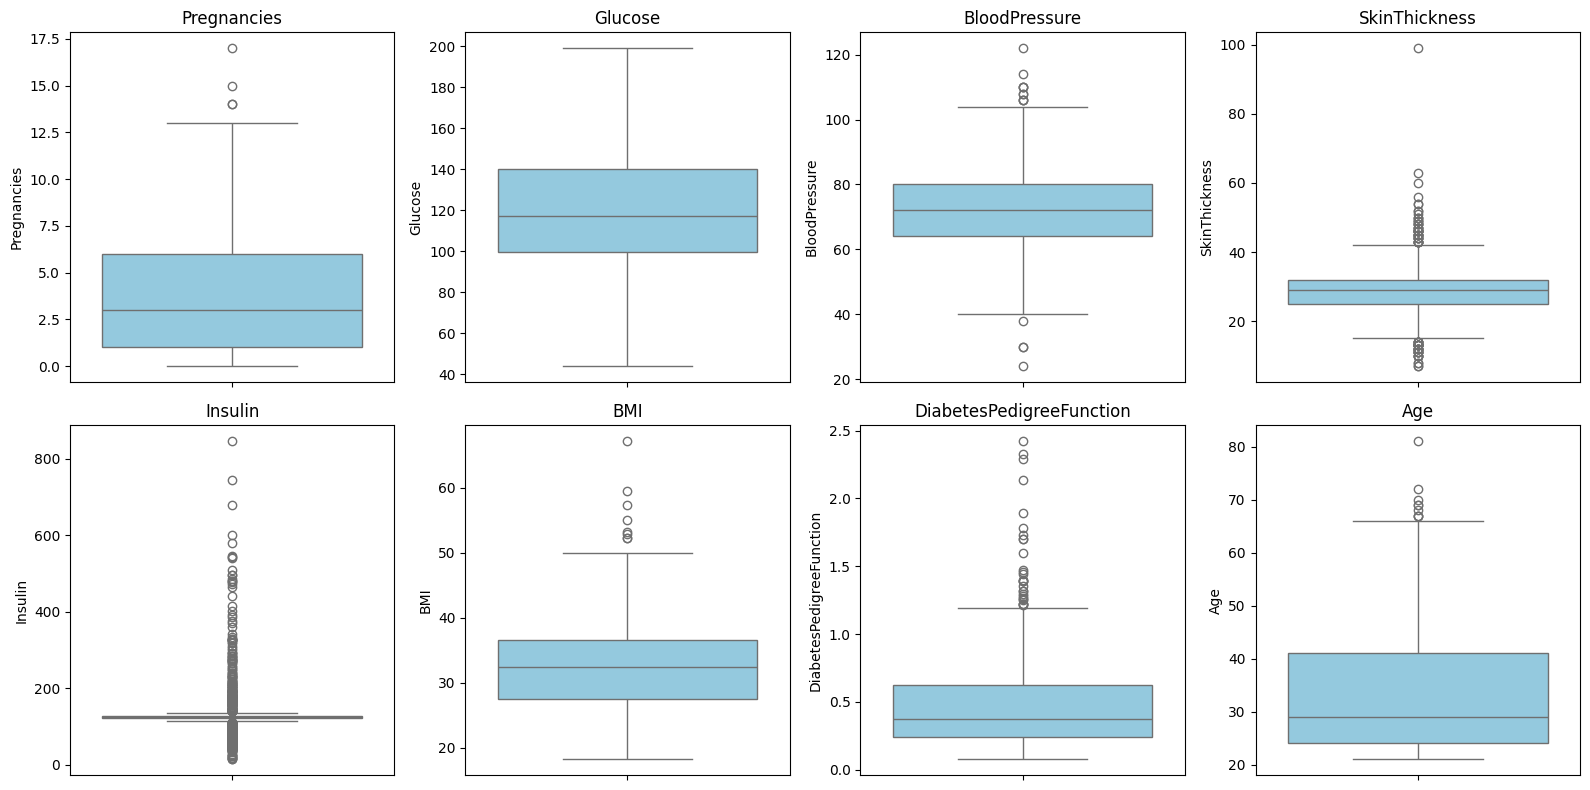

In [ ]:
numeric_cols = df_clean.columns.drop('Outcome')

# IQR method
outlier_summary = {}
for col in numeric_cols:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5*IQR, Q3 + 1.5*IQR
    outliers = df_clean[(df_clean[col] < lower) | (df_clean[col] > upper)]
    outlier_summary[col] = len(outliers)

print("Outlier count per column (IQR method):")
for k, v in outlier_summary.items():
    print(f"  {k}: {v}")

# Z-score method
z_scores = np.abs(stats.zscore(df_clean[numeric_cols]))
z_outliers = (z_scores > 3).sum(axis=0)
print("\nOutlier count per column (Z-score > 3):")
for col, cnt in zip(numeric_cols, z_outliers):
    print(f"  {col}: {cnt}")

# Box plots
plt.figure(figsize=(16, 8))
for i, col in enumerate(numeric_cols, 1):
    plt.subplot(2, 4, i)
    sns.boxplot(y=df_clean[col], color='skyblue')
    plt.title(col)
plt.tight_layout()
plt.show()


**7. Handle outliers using suitable preprocessing techniques.**

In [ ]:
df_capped = df_clean.copy()

for col in numeric_cols:
    Q1 = df_capped[col].quantile(0.25)
    Q3 = df_capped[col].quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5*IQR, Q3 + 1.5*IQR
    df_capped[col] = np.clip(df_capped[col], lower, upper)

print("Outliers handled via IQR capping. Summary statistics after capping:")
display(df_capped[numeric_cols].describe())


Outliers handled via IQR capping. Summary statistics after capping:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.837240,121.686763,72.376538,28.866536,124.691081,32.395615,0.458914,33.199870
std,3.344157,30.435949,11.696836,7.442353,7.913595,6.667466,0.285596,11.628404
min,0.000000,44.000000,40.000000,14.500000,112.875000,18.200000,0.078000,21.000000
25%,1.000000,99.750000,64.000000,25.000000,121.500000,27.500000,0.243750,24.000000
50%,3.000000,117.000000,72.202592,29.000000,125.000000,32.400000,0.372500,29.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000
max,13.500000,199.000000,104.000000,42.500000,135.875000,50.250000,1.200000,66.500000


**9. Apply feature scaling techniques: Min-Max Normalization  
Standardization (Z-score Scaling)**

In [ ]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler
features = df_capped[numeric_cols]
# Min-Max Normalization -> scales to [0,1]
minmax_scaler = MinMaxScaler()
df_minmax = pd.DataFrame(minmax_scaler.fit_transform(features), columns=numeric_cols)
# Standardization -> mean 0, std 1
standard_scaler = StandardScaler()
df_standard = pd.DataFrame(standard_scaler.fit_transform(features), columns=numeric_cols)
print("After Min-Max Normalization (sample):")
display(df_minmax.head())
print("\nAfter Standardization (sample):")
display(df_standard.head())


After Min-Max Normalization (sample):


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,0.444444,0.670968,0.50000,0.732143,0.527174,0.480499,0.489305,0.637363
1,0.074074,0.264516,0.40625,0.517857,0.527174,0.262090,0.243316,0.219780
2,0.592593,0.896774,0.37500,0.517857,0.527174,0.159126,0.529412,0.241758
3,0.074074,0.290323,0.40625,0.303571,0.000000,0.308892,0.079323,0.000000
4,0.000000,0.600000,0.00000,0.732143,1.000000,0.776911,1.000000,0.263736



After Standardization (sample):


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,0.647150,0.865108,-0.032212,0.824667,0.039062,0.180754,0.588927,1.445691
1,-0.848970,-1.206162,-0.545506,0.017945,0.039062,-0.869804,-0.378101,-0.189304
2,1.245598,2.015813,-0.716604,0.017945,0.039062,-1.365068,0.746595,-0.103252
3,-0.848970,-1.074652,-0.545506,-0.788777,-1.494110,-0.644685,-1.022787,-1.049828
4,-1.148194,0.503458,-2.769778,0.824667,1.414175,1.606512,2.596563,-0.017199


**10. Perform feature selection by identifying relevant attributes using correlation
analysis.  
11. Generate and interpret a correlation matrix and heatmap for the dataset.**

Correlation of each feature with target 'Outcome':
Outcome                     1.000000
Glucose                     0.492928
BMI                         0.312693
Insulin                     0.266382
Age                         0.242702
Pregnancies                 0.220392
SkinThickness               0.220111
DiabetesPedigreeFunction    0.184969
BloodPressure               0.169333
Name: Outcome, dtype: float64


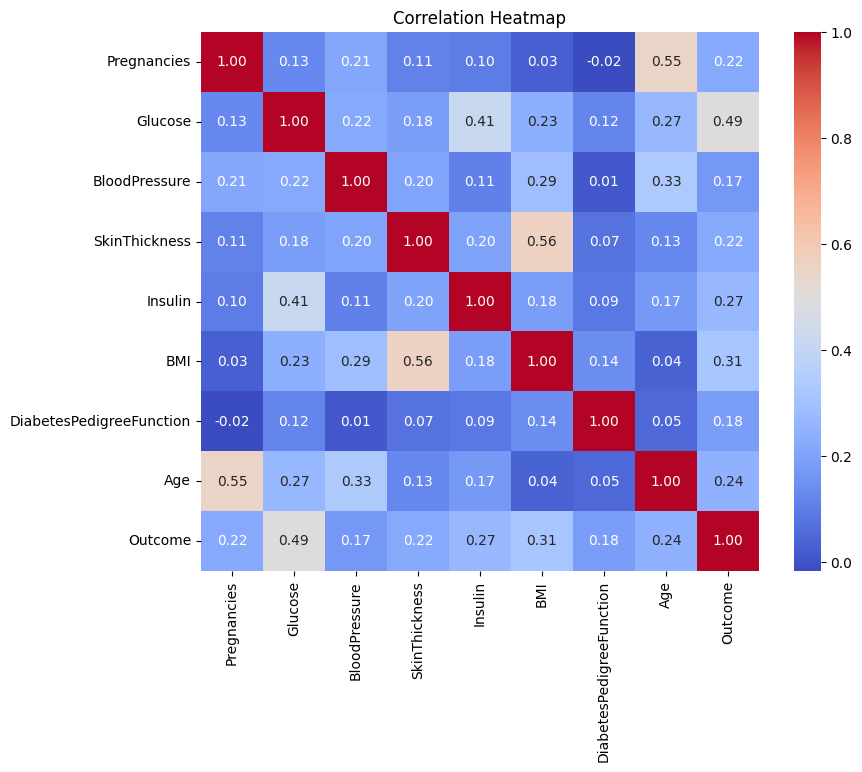

In [ ]:
corr_matrix = df_capped.corr()
print("Correlation of each feature with target 'Outcome':")
print(corr_matrix['Outcome'].sort_values(ascending=False))

plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Correlation Heatmap")
plt.show()

# Interpretation: Glucose, BMI, and Age typically show the strongest positive
# correlation with Outcome, making them the most relevant predictive features.


**13. Convert data types wherever necessary (e.g., string to datetime, integer to
float).**

In [ ]:
# Example conversions: Outcome -> categorical, Age -> int, Pregnancies -> int
df_capped['Outcome'] = df_capped['Outcome'].astype('category')
df_capped['Age'] = df_capped['Age'].astype(int)
df_capped['Pregnancies'] = df_capped['Pregnancies'].round().astype(int)

# Demonstrating a string -> datetime conversion (simulated 'record date' column)
df_capped['RecordDate'] = pd.date_range(start='2024-01-01', periods=len(df_capped), freq='D').astype(str)
df_capped['RecordDate'] = pd.to_datetime(df_capped['RecordDate'])

print(df_capped.dtypes)


Pregnancies                          int64
Glucose                            float64
BloodPressure                      float64
SkinThickness                      float64
Insulin                            float64
BMI                                float64
DiabetesPedigreeFunction           float64
Age                                  int64
Outcome                           category
RecordDate                  datetime64[ns]
dtype: object


**14. Handle inconsistent and noisy data by applying suitable cleaning techniques.**

In [ ]:
inconsistent = df_capped[(df_capped['BMI'] <= 0) | (df_capped['Age'] <= 0) | (df_capped['Glucose'] <= 0)]
print(f"Remaining inconsistent records found: {len(inconsistent)}")

df_capped.drop(columns=['RecordDate'], inplace=True)
print("Data is now consistent and ready for modeling.")


Remaining inconsistent records found: 0
Data is now consistent and ready for modeling.


**15. Split the dataset into training and testing sets using Scikit-learn.**

In [ ]:
from sklearn.model_selection import train_test_split
X = df_capped.drop(columns=['Outcome'])
y = df_capped['Outcome']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)


Training set shape: (614, 8)
Testing set shape: (154, 8)


**17. Visualize the distribution of numerical features before and after preprocessing.**

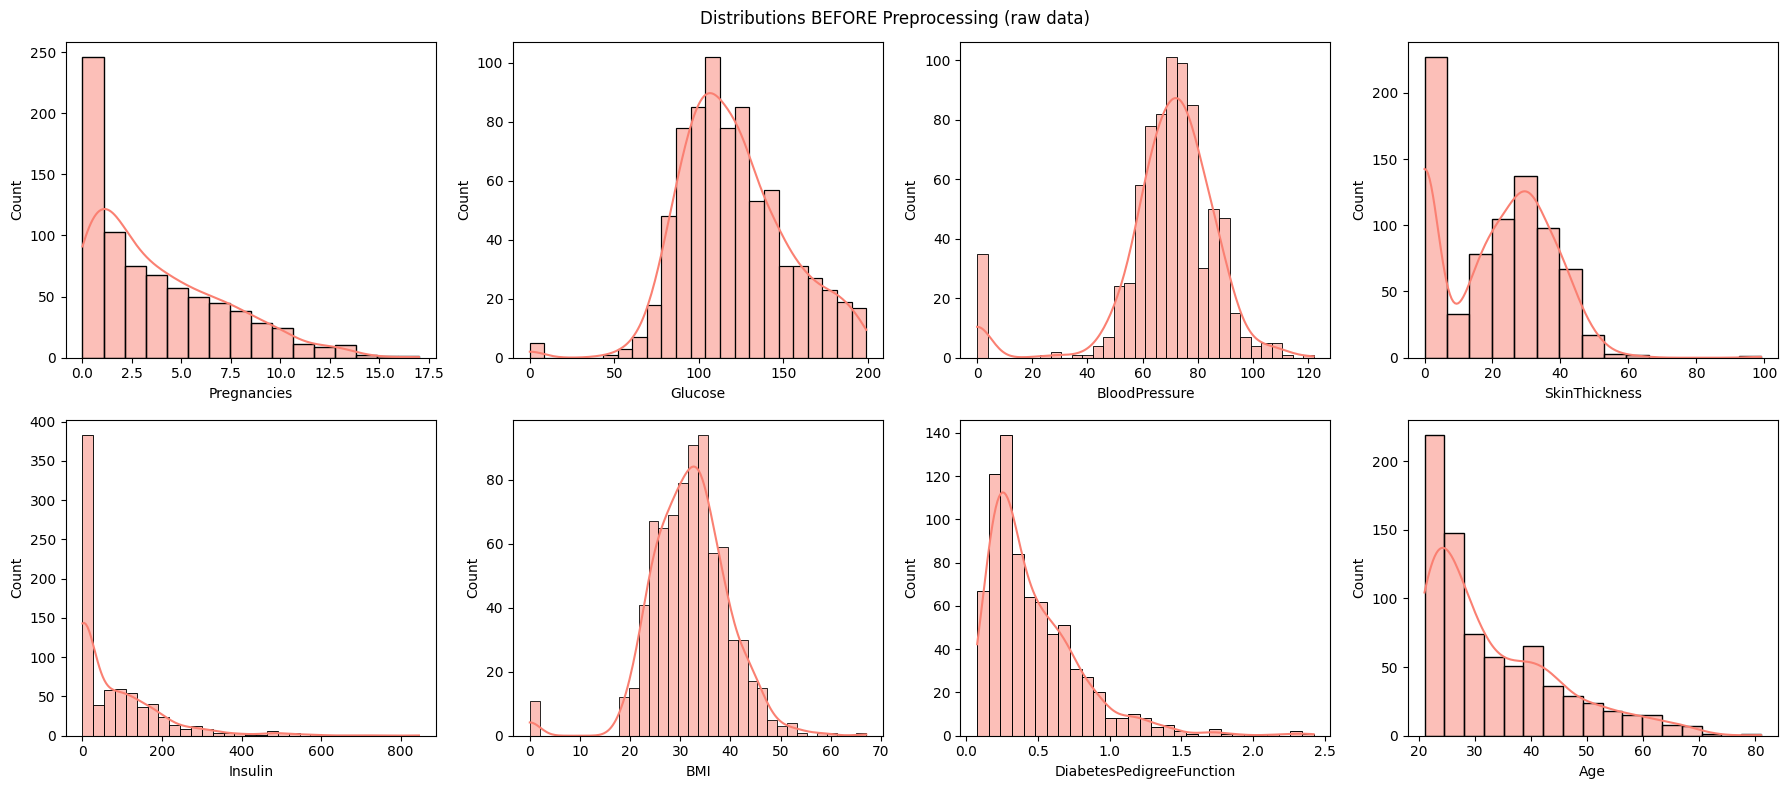

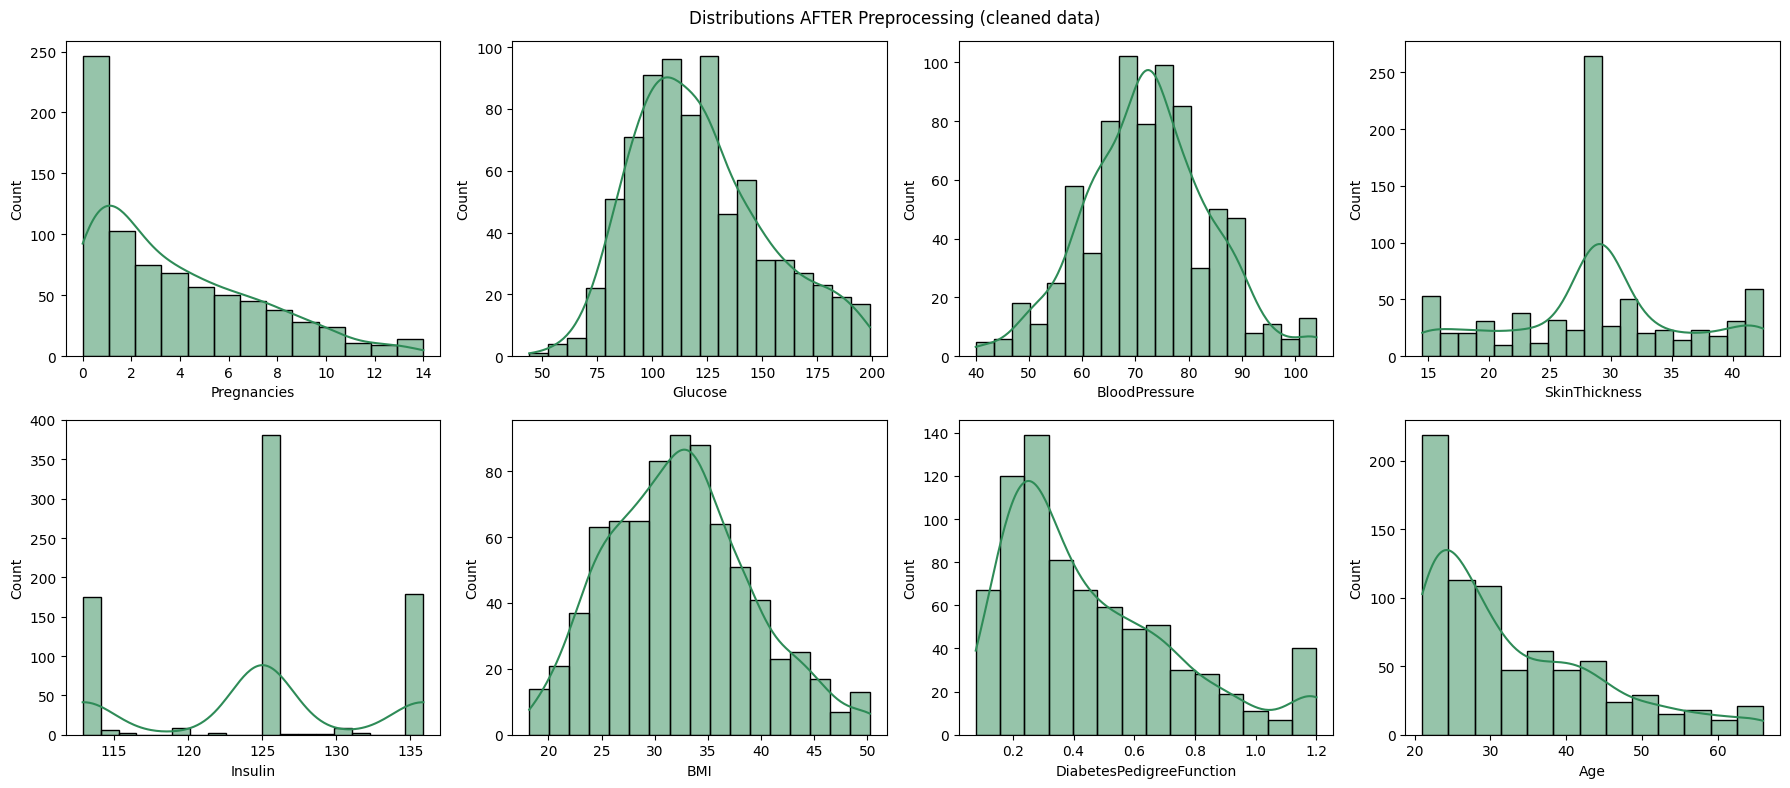

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for i, col in enumerate(numeric_cols):
    sns.histplot(df[col], kde=True, ax=axes[0, i%4] if i<4 else axes[1, i-4], color='salmon')
plt.suptitle("Distributions BEFORE Preprocessing (raw data)")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for i, col in enumerate(numeric_cols):
    sns.histplot(df_capped[col], kde=True, ax=axes[0, i%4] if i<4 else axes[1, i-4], color='seagreen')
plt.suptitle("Distributions AFTER Preprocessing (cleaned data)")
plt.tight_layout()
plt.show()


**18. Compare the dataset before and after preprocessing and summarize the changes made.**

In [ ]:
comparison = pd.DataFrame({
    "Metric": ["Rows", "Missing (hidden zero) values", "Duplicate rows", "Outliers (IQR, total)"],
    "Before": [
        df.shape[0],
        int((df[zero_cols] == 0).sum().sum()),
        df.duplicated().sum(),
        sum(outlier_summary.values())
    ],
    "After": [
        df_capped.shape[0],
        0,
        0,
        0
    ]
})
display(comparison)

print('''
Summary of changes made:
1. Hidden missing values (zeros) in Glucose, BloodPressure, SkinThickness, Insulin,
   and BMI were converted to NaN and imputed using mean/median.
2. Duplicate rows were identified and removed.
3. Outliers were detected using IQR and Z-score methods and capped (winsorized).
4. Numeric features were scaled using Min-Max Normalization and Standardization.
5. Data types were corrected (categorical Outcome, integer Age/Pregnancies).
6. The dataset was split into training (80%) and testing (20%) sets.
''')


,Metric,Before,After
0,Rows,768,768
1,Missing (hidden zero) values,652,0
2,Duplicate rows,0,0
3,"Outliers (IQR, total)",497,0



Summary of changes made:
1. Hidden missing values (zeros) in Glucose, BloodPressure, SkinThickness, Insulin,
   and BMI were converted to NaN and imputed using mean/median.
2. Duplicate rows were identified and removed.
3. Outliers were detected using IQR and Z-score methods and capped (winsorized).
4. Numeric features were scaled using Min-Max Normalization and Standardization.
5. Data types were corrected (categorical Outcome, integer Age/Pregnancies).
6. The dataset was split into training (80%) and testing (20%) sets.



**19. Save the cleaned and preprocessed dataset as a new CSV file.**

In [ ]:
df_capped.to_csv("diabetes_cleaned.csv", index=False)
print("Cleaned dataset saved as 'diabetes_cleaned.csv'")

# from google.colab import files
# files.download('diabetes_cleaned.csv')


Cleaned dataset saved as 'diabetes_cleaned.csv'
